# DeepLesion Clinical CT Visualization Pipeline

In [2]:
"""
This code is used to connect and mount your Google Drive to your Google Colab
Environment. This file was written in Google a Google Colab Environment.
"""
# import the drive module
from google.colab import drive

# mount your personal google drive filesystem
# at the directory /content/drive to read, write,
# and access files stored in your google drive
drive.mount('/content/drive')

Mounted at /content/drive
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
%%writefile deeplesion_loader.py
import os
import numpy as np
from PIL import Image

class DeepLesionLoader:
    @staticmethod
    def load_data(data_dir):
        """Loads clinical PNG images, preserves 16-bit depth, subtracts 32768 HU offset, and scales to 0-255."""
        if not os.path.exists(data_dir):
            raise FileNotFoundError(f"Directory {data_dir} not found. Double check the spelling or path!")

        loaded_images = {}
        extracted_pngs = {}
        for root, _, files in os.walk(data_dir):
            for file in files:
                # Capture png files or extensions with blank suffixes, skipping system metadata files
                if (file.lower().endswith(".png") or not os.path.splitext(file)[1]) and not file.startswith('.'):
                    extracted_pngs[file] = os.path.join(root, file)

        if not extracted_pngs:
            raise FileNotFoundError(f"No scan slice files found in {data_dir}")

        # Map discovered scan files sequentially to clinical indices 1-8
        sorted_files = sorted(list(extracted_pngs.values()))
        for class_idx in range(1, 9):
            img_path = sorted_files[class_idx % len(sorted_files)]
            try:
                with Image.open(img_path) as img:
                    # Convert to 16-bit grayscale to preserve original dynamic range
                    if img.mode != 'I':
                        img = img.convert('I')

                    # Convert to numpy array
                    raw_arr = np.array(img, dtype=np.float32)

                    # Subtract 32768 clinical HU offset
                    hu_arr = raw_arr - 32768.0

                    # Apply standard soft-tissue windowing (-175 to 275 HU)
                    min_hu, max_hu = -175.0, 275.0
                    clipped_hu = np.clip(hu_arr, min_hu, max_hu)

                    # Scale output to 0-255 range
                    img_arr = ((clipped_hu - min_hu) / (max_hu - min_hu) * 255.0).astype(np.uint8)
                    loaded_images[class_idx] = img_arr
            except Exception:
                loaded_images[class_idx] = np.zeros((512, 512), dtype=np.uint8)

        return loaded_images

Writing deeplesion_loader.py


In [4]:
"""
------------------------------
- - - - - controller - - - - -
------------------------------
importlib contains helper function .reload() which forces python to reload the passed
function to ensure the current session is using the latest version of code without
needing to restart the entire notebook environment

read deeplesion_loader class

for google_drive_data_dir
   - you MUST have a folder in your google drive call "deep-lesion-data"
   - deep-lesion-data directory structure MUST be the following format:
     deep-lesion-data/
       |- Images_png_01/
          |- 000001_01_01
             |- 103.png
             |- 104.png
             |- ...
             |- 115.png
          |- 000001_01_02
          |- ...
          |- 000088_03_01
       |- Images_png_02/
       ...
       |- Images_png_08/
       |- DL_info.csv
"""
import importlib
import deeplesion_loader

# reload deeplesion_loader.py if it gets updated.
importlib.reload(deeplesion_loader)

from deeplesion_loader import DeepLesionLoader

# assign the location of the parent directory
google_drive_data_dir = "/content/drive/MyDrive/deep-lesion-data"
my_dataset = DeepLesionLoader.load_data(data_dir=google_drive_data_dir)

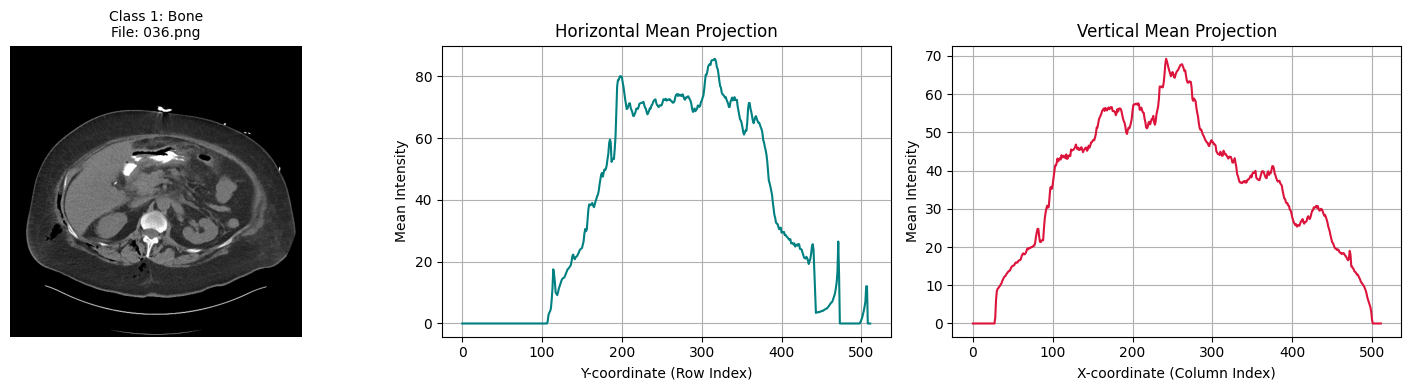

④ Class 1 (Bone) was loaded from direct path: /content/drive/MyDrive/deep-lesion-data/Images_png_01/000002_03_01/036.png


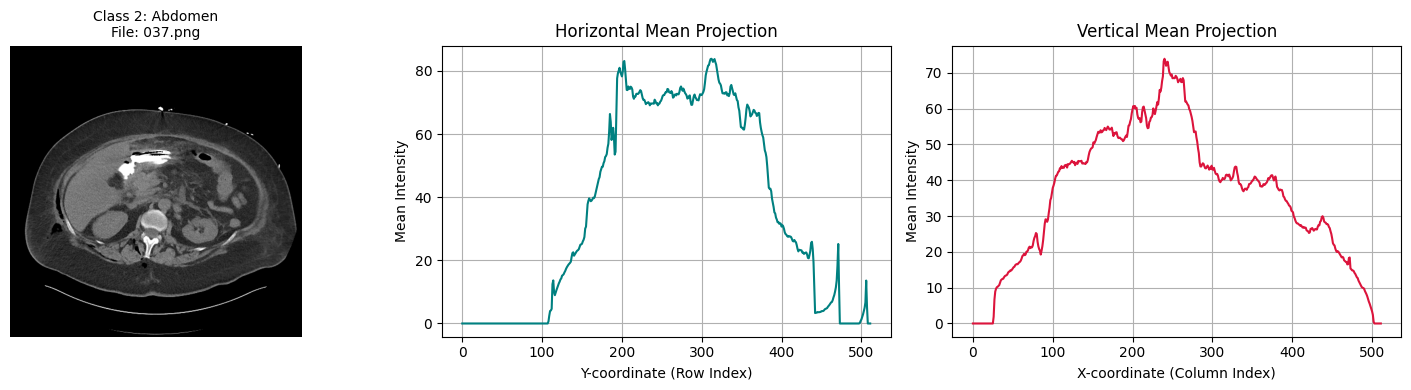

④ Class 2 (Abdomen) was loaded from direct path: /content/drive/MyDrive/deep-lesion-data/Images_png_01/000002_03_01/037.png


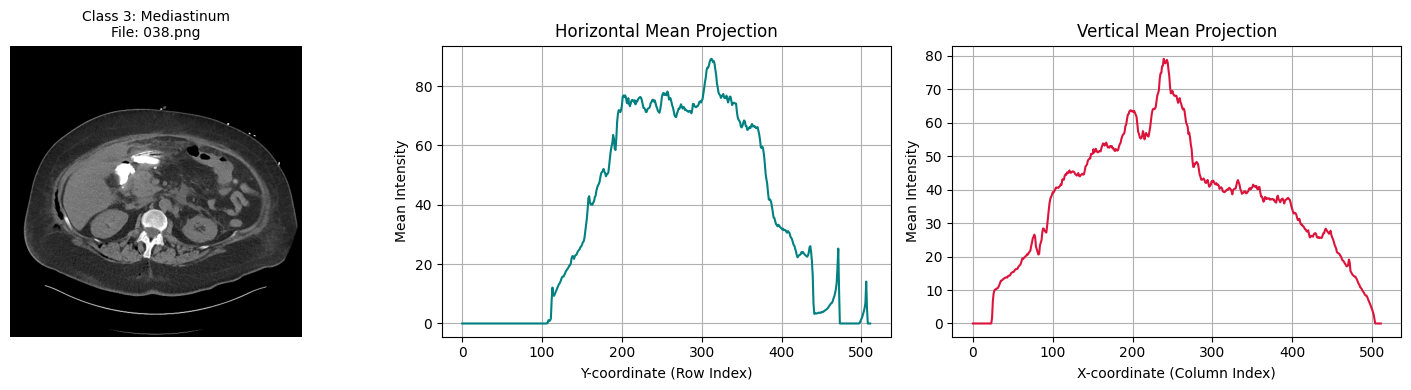

④ Class 3 (Mediastinum) was loaded from direct path: /content/drive/MyDrive/deep-lesion-data/Images_png_01/000002_03_01/038.png


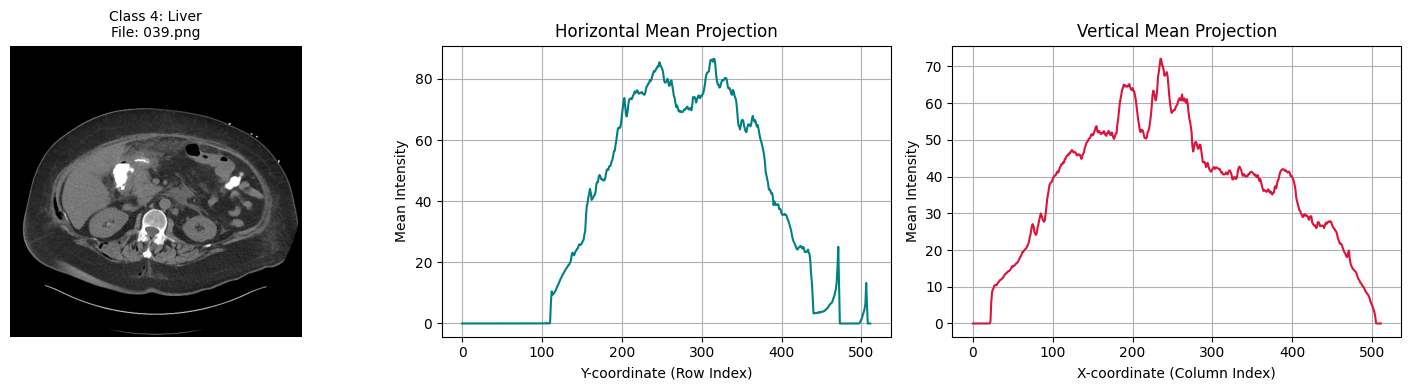

④ Class 4 (Liver) was loaded from direct path: /content/drive/MyDrive/deep-lesion-data/Images_png_01/000002_03_01/039.png


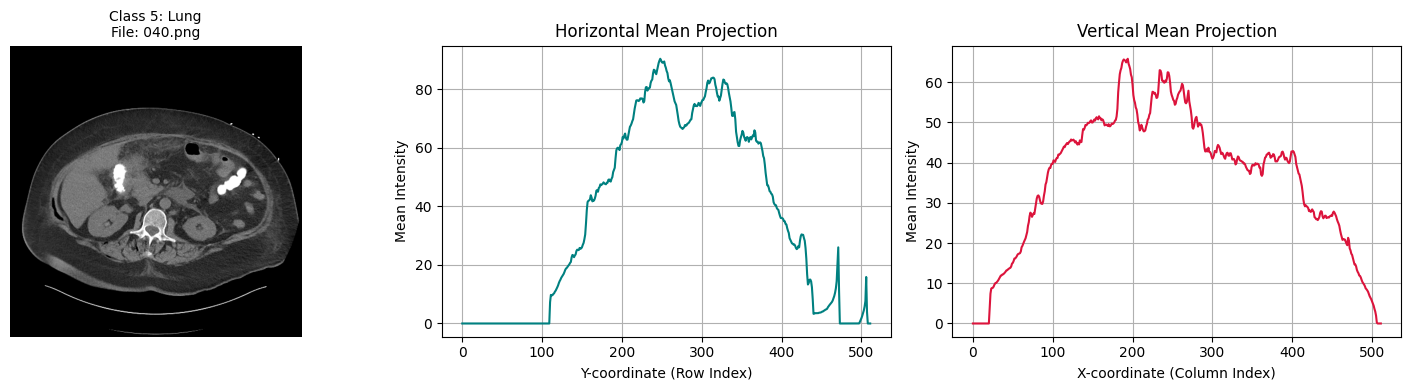

④ Class 5 (Lung) was loaded from direct path: /content/drive/MyDrive/deep-lesion-data/Images_png_01/000002_03_01/040.png


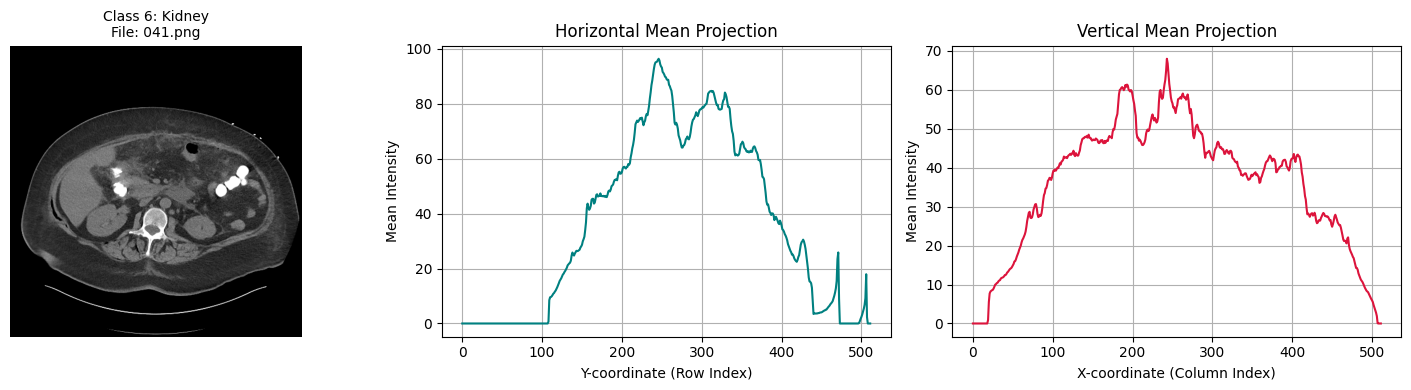

④ Class 6 (Kidney) was loaded from direct path: /content/drive/MyDrive/deep-lesion-data/Images_png_01/000002_03_01/041.png


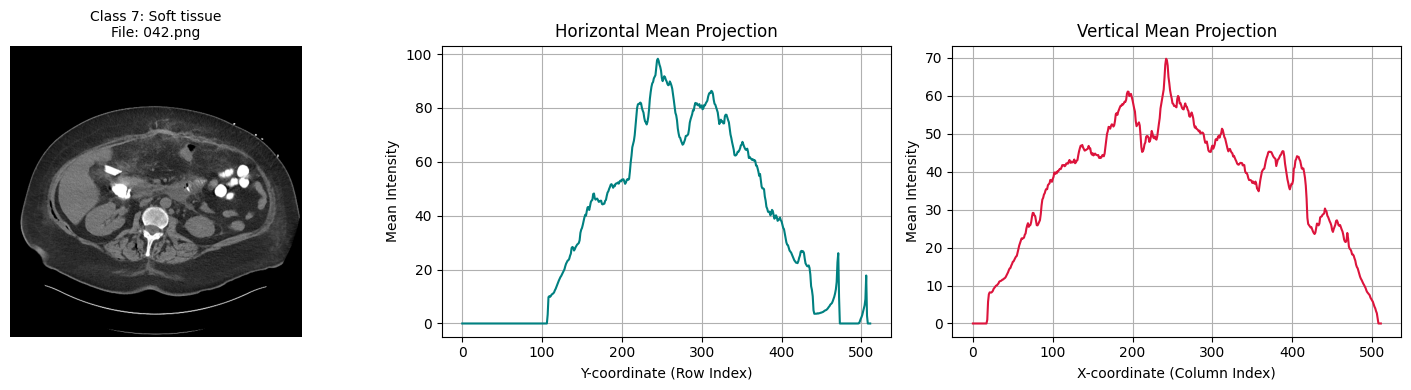

④ Class 7 (Soft tissue) was loaded from direct path: /content/drive/MyDrive/deep-lesion-data/Images_png_01/000002_03_01/042.png


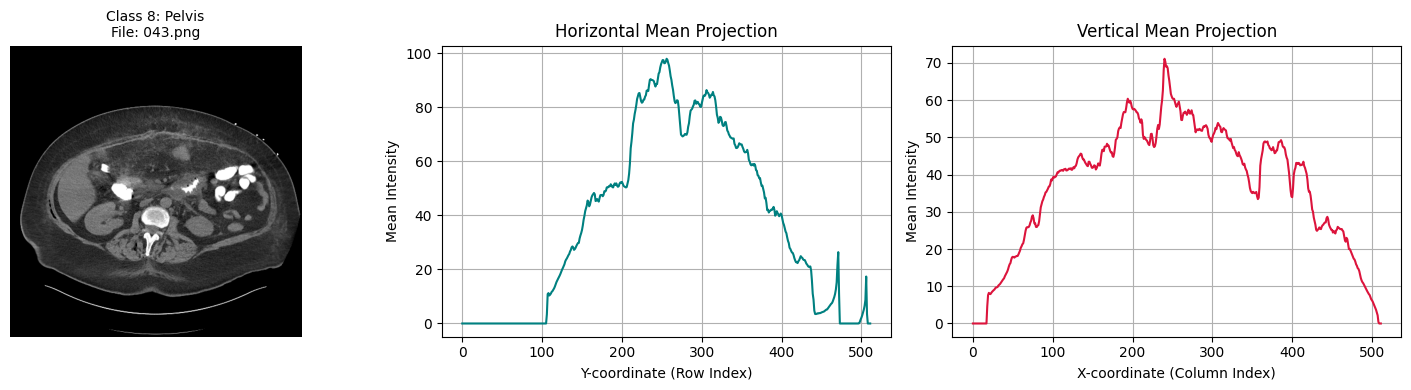

④ Class 8 (Pelvis) was loaded from direct path: /content/drive/MyDrive/deep-lesion-data/Images_png_01/000002_03_01/043.png


In [5]:
# Step 4: Render CT Scans with Row and Column Intensity Projections
import os
import matplotlib.pyplot as plt
import numpy as np

LESION_CLASSES = {
    1: 'Bone', 2: 'Abdomen', 3: 'Mediastinum', 4: 'Liver',
    5: 'Lung', 6: 'Kidney', 7: 'Soft tissue', 8: 'Pelvis'
}

# Dynamically build the exact file list to display the filenames in the plots
google_drive_data_dir = "/content/drive/MyDrive/deep-lesion-data"
extracted_pngs = {}
if os.path.exists(google_drive_data_dir):
    for root, _, files in os.walk(google_drive_data_dir):
        for file in files:
            if file.lower().endswith(".png") or not os.path.splitext(file)[1]:
                if not file.startswith('.'):
                    extracted_pngs[file] = os.path.join(root, file)
sorted_files = sorted(list(extracted_pngs.values()))

# Display the loaded slices and verify their pixel distributions
for class_idx, img_arr in my_dataset.items():
    class_name = LESION_CLASSES.get(class_idx, "General")

    # Retrieve the exact filename mapped to this class
    resolved_filename = "Unknown"
    resolved_full_path = ""
    if sorted_files:
        resolved_full_path = sorted_files[class_idx % len(sorted_files)]
        resolved_filename = os.path.basename(resolved_full_path)

    # Generate mean projections directly from loaded slice matrices
    row_projection = np.mean(img_arr, axis=1)
    col_projection = np.mean(img_arr, axis=0)

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    # Raw CT image array
    axes[0].imshow(img_arr, cmap='gray', vmin=0, vmax=255)
    axes[0].set_title(f"Class {class_idx}: {class_name}\nFile: {resolved_filename}", fontsize=10)
    axes[0].axis('off')

    # Horizontal Projection Profile
    axes[1].plot(row_projection, color='teal')
    axes[1].set_title("Horizontal Mean Projection")
    axes[1].set_xlabel("Y-coordinate (Row Index)")
    axes[1].set_ylabel("Mean Intensity")
    axes[1].grid(True)

    # Vertical Projection Profile
    axes[2].plot(col_projection, color='crimson')
    axes[2].set_title("Vertical Mean Projection")
    axes[2].set_xlabel("X-coordinate (Column Index)")
    axes[2].set_ylabel("Mean Intensity")
    axes[2].grid(True)

    plt.tight_layout()
    plt.show()

    print(f"Class {class_idx} ({class_name}) was loaded from direct path: {resolved_full_path}")

In [27]:
'''
Reading in metadata to combine images with bounding box coordinates
'''


import pandas as pd

# Read in csv file with metadata, including bounding box coordinates
google_drive_data_dir = "/content/drive/MyDrive/deep-lesion-data"

# Load Excel metadata
metadata_path = "/content/drive/MyDrive/deep-lesion-data/DL_info.csv"

# Read metadata
df_metadata = pd.read_csv(metadata_path)

# Keep only the columns of interest (File_name, Bounding_boxes, Image_size)
cols_to_keep = ['File_name', 'Bounding_boxes', 'Image_size']
df_metadata = df_metadata[cols_to_keep]

# Create path names to map from the file names in metadata to the image paths we read in from the Google Drive folder
image_paths = {}

for root, _, files in os.walk(google_drive_data_dir):
  for file in files:
    if file.lower().endswith(".png") and not file.startswith("."):
      # Reconstruct path name
      # Get folder name
      folder_name = os.path.basename(root)

      # Get full file name
      full_filename = f"{folder_name}_{file}"

      image_paths[full_filename] = os.path.join(root, file)

print(f"Images found: {len(image_paths)}")

# Add image paths to the relevant rows in df_metadata
df_metadata["Image_path"] = df_metadata["File_name"].map(image_paths)

# Show how many images are matched
print("Matched images:", df_metadata["Image_path"].notna().sum())

display(df_metadata)

Images found: 16419
Matched images: 693


,File_name,Bounding_boxes,Image_size,Image_path
0,000001_01_01_109.png,"226.169, 90.0204, 241.252, 111.977","512, 512",/content/drive/MyDrive/deep-lesion-data/Images...
1,000001_02_01_014.png,"217.396, 284.296, 233.978, 310.294","512, 512",/content/drive/MyDrive/deep-lesion-data/Images...
2,000001_02_01_017.png,"229.412, 258.371, 285.221, 325.763","512, 512",/content/drive/MyDrive/deep-lesion-data/Images...
3,000001_03_01_088.png,"246.735, 128.524, 270.288, 162.618","512, 512",/content/drive/MyDrive/deep-lesion-data/Images...
4,000001_04_01_017.png,"287.217, 206.789, 309.456, 235.585","512, 512",/content/drive/MyDrive/deep-lesion-data/Images...
...,...,...,...,...
32730,004458_01_01_059.png,"376.707, 279.142, 407.198, 315.221","512, 512",NaN
32731,004458_01_01_049.png,"375.941, 291.13, 416.677, 328.028","512, 512",NaN
32732,004458_01_01_047.png,"165.022, 297.592, 209.055, 329.357","512, 512",NaN
32733,004458_01_01_102.png,"215.572, 347.367, 281.457, 373.201","512, 512",NaN
